# Week 1 Task 5 — A real time series

This notebook follows the Week 1 assignment brief and keeps each task in a separate file.

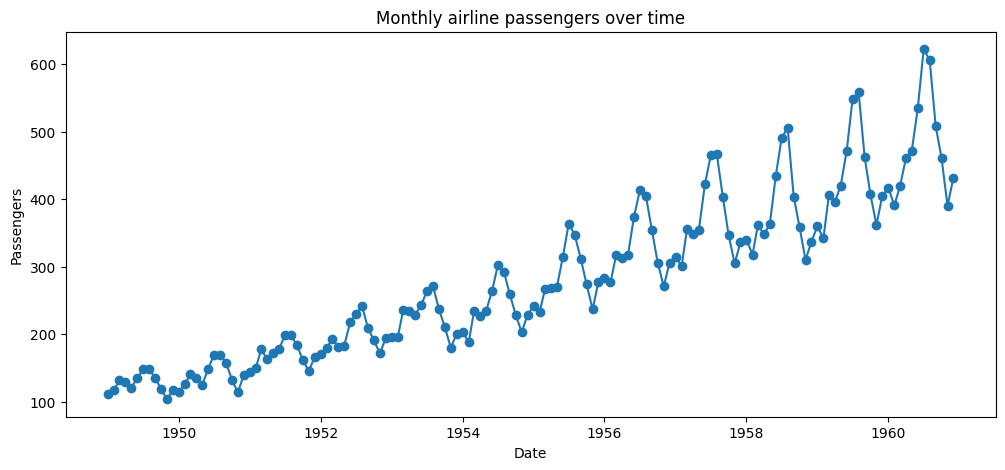

In [4]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

path = Path('week1/assignments/data/flights.csv')
if not path.exists():
    path = Path('assignments/data/flights.csv')
if not path.exists():
    path = Path('d:/7_Semester/data-visualization/week1/assignments/data/flights.csv')

month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
month_map = {m: i + 1 for i, m in enumerate(month_order)}
df = pd.read_csv(path)
df['month_num'] = df['month'].map(month_map)
df['date'] = pd.to_datetime(df['year'].astype(str) + '-' + df['month_num'].astype(str).str.zfill(2) + '-01')
df = df.sort_values('date').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df['date'], df['passengers'], color='tab:blue', marker='o')
ax.set_title('Monthly airline passengers over time')
ax.set_xlabel('Date')
ax.set_ylabel('Passengers')
plt.show()

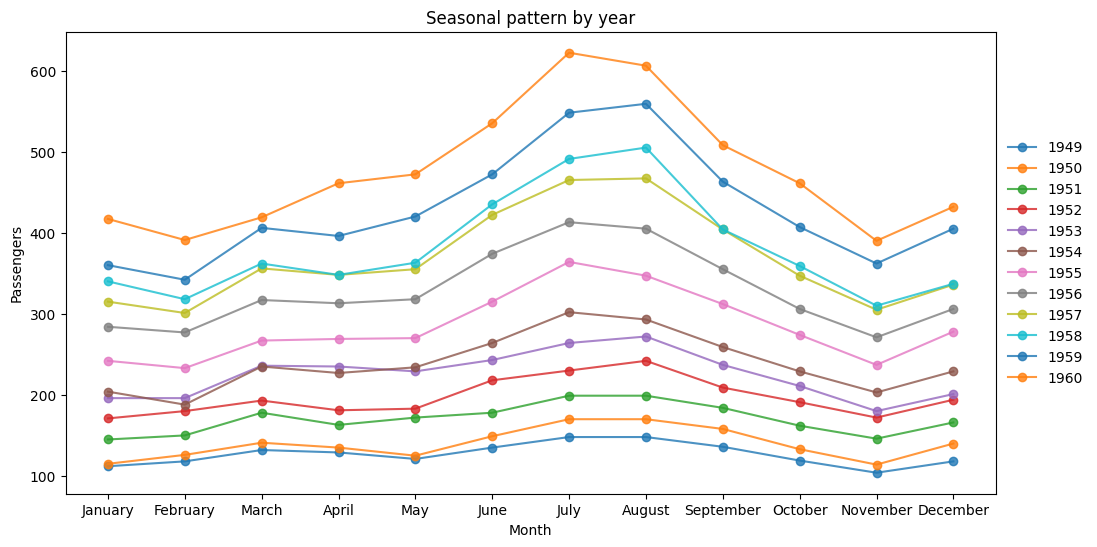

In [2]:
seasonal = df.pivot_table(index='month', columns='year', values='passengers', aggfunc='first').reindex(month_order)
fig, ax = plt.subplots(figsize=(12, 6))
for year in seasonal.columns:
    ax.plot(seasonal.index, seasonal[year], marker='o', linewidth=1.5, alpha=0.8, label=str(year))
ax.set_title('Seasonal pattern by year')
ax.set_xlabel('Month')
ax.set_ylabel('Passengers')
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

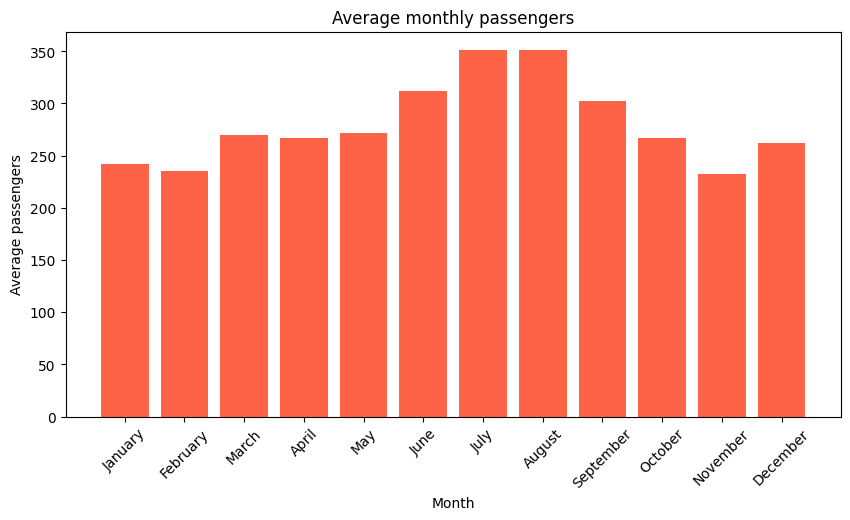

In [3]:
mean_by_month = df.groupby('month', observed=False)['passengers'].mean().reindex(month_order)
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(mean_by_month.index, mean_by_month.values, color='tomato')
ax.set_title('Average monthly passengers')
ax.set_xlabel('Month')
ax.set_ylabel('Average passengers')
plt.xticks(rotation=45)
plt.show()

In [ ]:
# The first chart captures long-term growth, the second isolates the seasonal pattern, and the third makes the busiest month obvious. The seasonal swing can be larger simply because the level of traffic is larger, so a chart of monthly index values or a decomposition would help separate the two effects.